# Lab #3: Asking a statistical question

    Saraliba Auch
    10/22/2026

This week we are going to concentrate on asking a statistical question. This process almost always consists of 3+ steps:

1. Writing down in words very precisely what question you are trying to ask.
2. Translating the precise english question into a mathematical expression. This often includes determining the pdf of the background (possibly including trials), and the to integral to do to obtain a probability.
3. Coverting the probability into equivalent sigma

So in this lab we will assume that we know the form of the signal-free background distribution (determining a distribution from data will be next week's lab). In each of our three examples, your task will be to state the statistical question, convert it to math, then perform the associated analyses.

## **Problem 1**

In our first example we are looking at the temperature reading (meta-data) associated with an experiment. For the experiment to work reliably, the temperature should be at around 12 Kelvin, and if we look at the data it is mostly consistent with 12 Kelvin to within the 0.4 degree precision of the thermometry and the thermal control system (standard deviation). However, there are times when the thermal control system misbehaved and the temperature was not near 12 K, and in addition there are various glitches in the thermometry that give anomalously high and low readings (the reading does not match the real temperature). We definitely want to identify and throw out all the data when the thermal control system was not working (and the temperature was truly off from nominal). While it is possible to have an error in the thermometry such that the true temperature was fine, and we just had a wonky reading, in an abundance of caution we want to throw those values out too.

In [2]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (5,5)

To make this a bit concrete, we will simulate a little data. Start by simulating 100k 'good' data points assuming Gaussian fluctations, and because we are playing god adding the following 'bad' datapoints: {10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7}

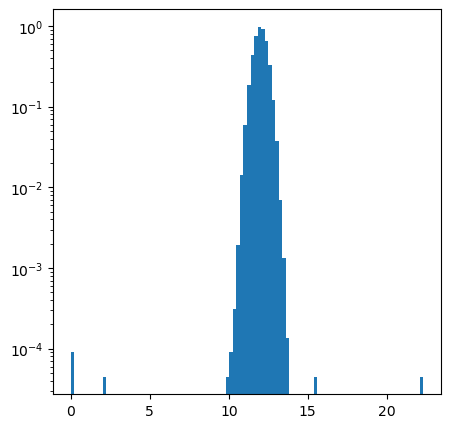

In [4]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.yscale('log')

plt.show()

**A) So our goal is to identify bad data and throw it out.**

0. **Start by exploring the data you have created with appropriate plots**
1. **State the statistical question in words. Be very clear, and describe why you have chosen this statistical question.**
2. **Restate your question in math. Be very clear.**
3. **Apply your statistical test and construct a truth table.**

    1. How many temperature readings are three sigma and higher away from the mean temperture of 12 Kelvin? This should hopfully eliminate the times the thermal control system misbehaved, and when the thermetry gliched. 

    2. How many temperture readings are between -infinity to -3 sigma and 3 sigma to infinity for the given distribution?

In [5]:
#Calculates the probability of a 3-sigma event
d_sf = stats.norm.sf(3)
#Calcules the value the cooresponds to the probability on the temperture reading distribution. 
d_isf1 = stats.norm.isf(d_sf, loc = 12., scale = 0.4)
#same thing above but for 3 sigma
d_sf = stats.norm.sf(-3)
d_isf2 = stats.norm.isf(d_sf, loc = 12., scale = 0.4)
#sanity check: these values make sense
print(d_isf1)
print(d_isf2)

13.2
10.8


In [6]:
#Calculates the number of readings counts as "bad"
print(np.count_nonzero(d > d_isf1))
print(np.count_nonzero(d < d_isf2))

134
127


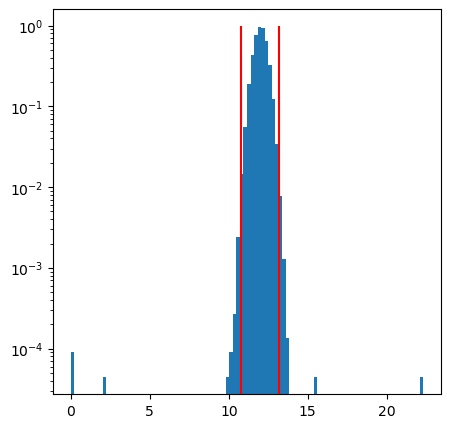

In [7]:
#Visulaization of what data is cut off
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.yscale('log')

ax.vlines(d_isf1,0,1,color='red')
ax.vlines(d_isf2,0,1,color='red')
plt.show()

|  | True T| Bad T |
| --- | --- | --- |
| Your Test Good | 99,726 | 1 |
| Your Test Bad | 274 | 7 |

The idea is how often you kept the known good data (True T & Your Test Good), how often you correctly discarded bad data (Bad T & Your Test Bad), and how often mistakes were made of either omission or commission (off diagonals).

**B) How does the number of omissions, where you threw out good data, depend on the statistical threshold you chose and is it a predictable quantity?**

    Yes, the simga I chose effects how much good data is thrown out.
    It is predictible, since the distribution follows a mostly Gaussian distribution with a few outliers.

**C) Are there mistakes of commission (bad data getting in)? If yes, are they avoidable and how do they depend on your statistical threshold?**

    Yes, my statistical test read one of the bad values as good. If I wanted to completely avoid bad data, I would have to cut out a lot of good data. This would be done by cutting out data above a lower sigma. I would not consider it worth it to do this. 

## Problem 2

In this example we will be looking for asteroids. If we look at the alignment of stars on subsequent images, they don't perfectly align due to atmospheric and instrumental effects (even ignoring proper motion). The resulting distribution is two dimensional, and for this lab let's assume it is a 2D Gaussian with 1 arcsecond RMS. Or said another way, if I histogram how far all the (stationary) stars appear to have moved I get something like:

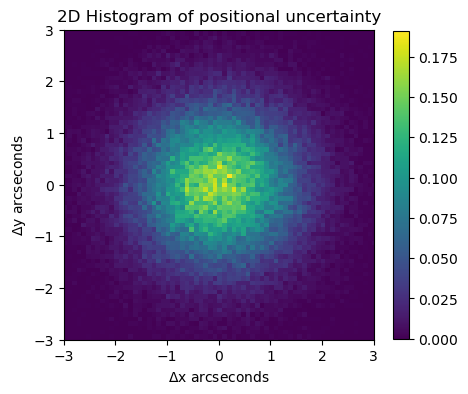

In [36]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty")
plt.ylabel(r"$\Delta$y arcseconds")
plt.xlabel(r"$\Delta$x arcseconds")
plt.colorbar(h[3], ax=ax, shrink=.80)

**If I have a potential asteroid, it will have some true movement between the images. We would like a '5 sigma' detection of movement. What is that distance in arcseconds?**

**1. What is the question in words?**

    How many arcseconds would an object have to move in order to declare I have found an asteroid (5 sigma).

**2. What is the question in math? [Hint: Come up with an analytic description of your pdf(). The Blue Book may be helpful here.]**

    The distance is just the amplitude of a vector for a 2D Gaussian. Since the 2D Gaussian is made up of two standard normal distribution, the amplitude would just be a Rayleigh distribution. There, my question in math is:
    What value cooresponds to 5 simga on a Rayleigh distribution? 

**3. What distance in arcseconds represents a 5 sigma detection of motion?**

In [8]:
prob = stats.norm.sf(5)
ray_isf = stats.rayleigh.isf(prob)

print(f"An object would have to move {ray_isf:.2f} arcseconds in order for it be considered true movement")

An object would have to move 5.49 arcseconds in order for it be considered true movement


## Problem 3

As we discussed in class, one of the key backgrounds for gamma-ray telescopes are cosmic rays. Cosmic rays are charged particles—usually protons or electrons but can include atomic nuclei such a alpha particles (helium) or iron. Because of their charge cosmic rays spiral in the magnetic field of the galaxy. From the perspective of the Earth they appear to be coming uniformly from all directions like a high energy gas, and the direction the cosmic ray is travelling when it reaches the Earth tells us nothing about where it came from because we don't know what tortured path it has taken through the galaxy to reach us. However, at trillion electron volt energies and above, the spiral loops are fairly big and the sun and the moon will block cosmic rays. This means the sun and the moon appear as holes in the cosmic ray sky (cosmic rays from that direction are absorbed).

Assume in a moon sized patch on the sky we normally have a cosmic ray rate of 1 cosmic ray per minute (arrivals are random in time). If we can observe where the moon is for 8 hours per night (not too close to the horizon) and we observe for 15 days and see 6800 cosmic rays, what is the signficance of our moon shadow detection?

As always:

**1. What is the question in words?**

    What is the probability of the background producing 6800 cosmic rays in moon sized spot on the sky over the course of 8 hours a night for 15 nights?

**2. Translate the question to math, describing both the expected background pdf() and the integral you need to do.**

    1. I need to figure out what distributon the gamma-rays will follow. Since they are disrcrete and rare, they will follow a Poisson distribution. 
    
PMF(x) = ${\displaystyle {\frac {\lambda ^{x}e^{-\lambda }}{x!}}}$

    2. I know that when summing Poisson distributions distribution, the mean will just be N*lambda where N is the number of times I sum the distributions and lambda is the original mean.
PMF'(x') = ${\displaystyle {\frac {(N\lambda) ^{x'}e^{-N\lambda}}{x'!}}}$

    3. Then I would find the probability of finding 6800 cosmic rays given the new ditribution. This would just be the CDF of the Poisson distribution, or integrating the pdf from 0 to 6800. 
CDF = ${\displaystyle e^{-N\lambda}\sum _{j=0}^{6800}{\frac {(N\lambda)^{j}}{j!}},}$

    4. Lastly, I would apply that probability to a standard normal distribution. This would be the PPF of a standard normal distribution



**3. Convert to sigma.**

Text(0, 0.5, 'Probability')

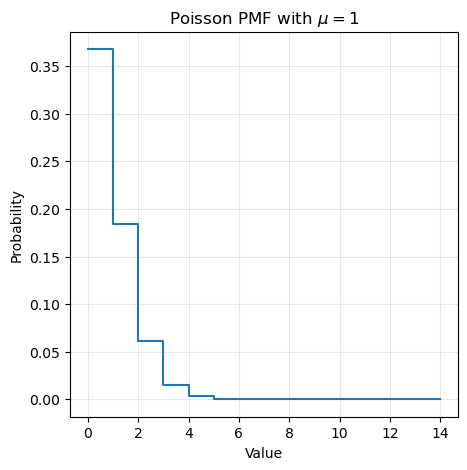

In [9]:
#creats a discrete distribution
dist = np.arange(0,15,1)
mean = 1 #Average of 1 cosmic ray per minute
poss_pmf = stats.poisson.pmf(dist, mean)

#plot of the distribution
fig, axes = plt.subplots(figsize=(5, 5))
axes.step(dist, 
             poss_pmf)
axes.grid(alpha=0.3)
axes.set_title(r"Poisson PMF with $\mu=1$")
axes.set_xlabel("Value")
axes.set_ylabel("Probability")

Text(0, 0.5, 'Probability')

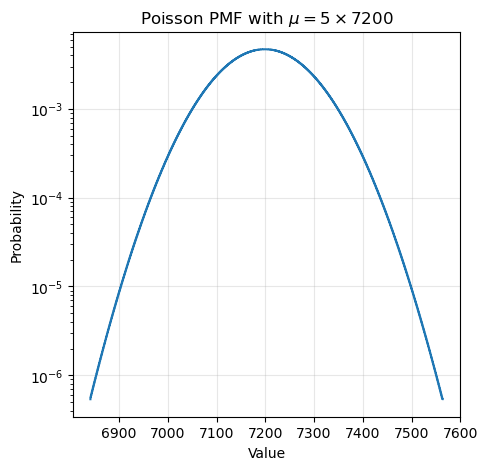

In [24]:
#Want to turn the 8 hours every night for 15 nights into minutes
num_min = 15 * 8 * 60
#make a new ditribution to ensure it has a large enough range
new_dist = np.arange(stats.poisson.ppf(0.00001, num_min*mean), 
                     stats.poisson.ppf(0.99999, num_min*mean))
#Poisson PMF for the 15 nights
new_pmf = stats.poisson.pmf(new_dist, num_min*mean)

#plot of the distribution
fig, axes = plt.subplots(figsize=(5, 5))
axes.step(new_dist, 
          new_pmf)
axes.grid(alpha=0.3)
axes.set_yscale('log')
axes.set_title(r"Poisson PMF with $\mu=5 \times 7200$")
axes.set_xlabel("Value")
axes.set_ylabel("Probability")

In [23]:
#CDF integrates from left to right
poss_cdf = stats.poisson.cdf(6800, mu=num_min*mean)
#PPF will find the corresponding sigma
poss_ppf = stats.norm.ppf(poss_cdf)
print(f'the simga is {poss_ppf:.2f}')

the simga is -4.75


There are some unique aspects to this problem. Make sure you explore them in your explanation.